<a href="https://colab.research.google.com/github/thanhf16hehe-droid/tuan2_phanchithanh/blob/main/tuan2_bai1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# THỰC HÀNH HỒI QUY TRÊN DỮ LIỆU DIABETES

- Bài 1: Khám phá 3 feature: bmi, bp và s5.
- Bài 2: So sánh Linear Regression với các bộ feature khác nhau.
- Bài 3: So sánh các thuật toán hồi quy.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)

diabetes = load_diabetes(as_frame=True)

X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


# BÀI 1. KHÁM PHÁ DỮ LIỆU

Chọn 3 feature: bmi, bp và s5.

## 1. Phân phối

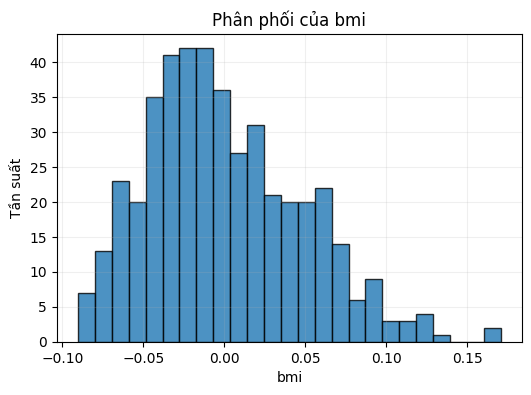

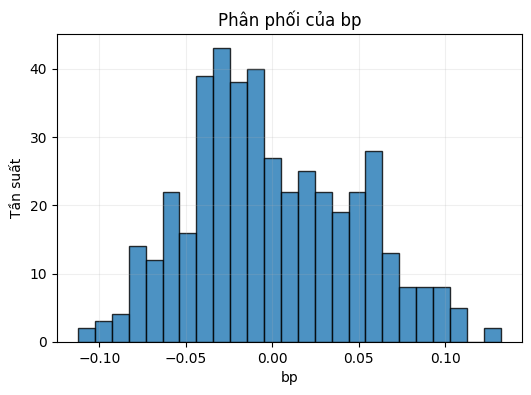

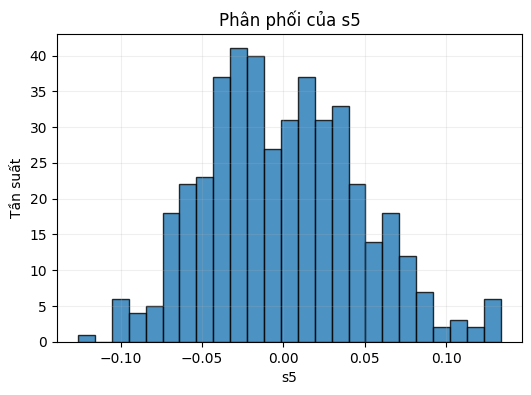

In [ ]:
feature_cols = ["bmi", "bp", "s5"]

for col in feature_cols:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=25, edgecolor="black", alpha=0.8)
    plt.title(f"Phân phối của {col}")
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.grid(alpha=0.2)
    plt.show()

bmi: Phân phối lệch phải, các giá trị tập trung chủ yếu trong khoảng −0.05 đến 0.05. Đuôi bên phải kéo dài đến khoảng 0.17, cho thấy có một số mẫu mang giá trị BMI chuẩn hóa cao.

bp: Phân phối hơi lệch phải, phần lớn giá trị nằm trong khoảng −0.05 đến 0.06. Tần suất cao nhất ở vùng khoảng −0.03; các cột cao thấp không đều.

s5: Phân phối khá cân đối quanh 0, phần lớn giá trị nằm trong khoảng −0.06 đến 0.06. Hai phía có ít mẫu ở xa vùng trung tâm.

## 2. Phát hiện ngoại lệ bằng IQR

Mã: đếm ngoại lệ

In [ ]:
outlier_summary = []

for col in feature_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Số ngoại lệ theo IQR", "Ngưỡng dưới", "Ngưỡng trên"]
)

display(outlier_df)

,Biến,Số ngoại lệ theo IQR,Ngưỡng dưới,Ngưỡng trên
0,bmi,3,-0.132445,0.129464
1,bp,0,-0.145106,0.144094
2,s5,4,-0.131762,0.130949


Nhận xét về ngoại lệ (Outliers):
Based on the IQR calculation results:

bmi: Có 3 ngoại lệ vượt quá ngưỡng trên ( 0.129 ). Đây là những mẫu có chỉ số BMI rất cao so với phần còn lại của tập dữ liệu.
bp (huyết áp): Không phát hiện ngoại lệ nào (0 ngoại lệ), các giá trị hoàn toàn nằm trong khoảng an toàn từ  −0.145  đến  0.144 .
s5: Có 4 ngoại lệ (các điểm dữ liệu nằm ngoài khoảng  −0.132  đến  0.131 ), cho thấy một vài bệnh nhân có mức chỉ số s5 đặc biệt cao hoặc thấp.
Nhìn chung, số lượng ngoại lệ rất ít so với tổng số 442 mẫu, dữ liệu khá sạch và không cần xử lý loại bỏ ngoại lệ quá phức tạp trước khi xây dựng mô hình hồi quy.

## 3. Tương quan với target và scatter plot

,corr_with_target
bmi,0.586450
s5,0.565883
bp,0.441482


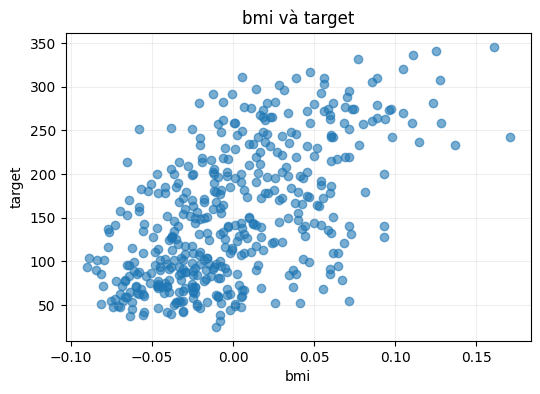

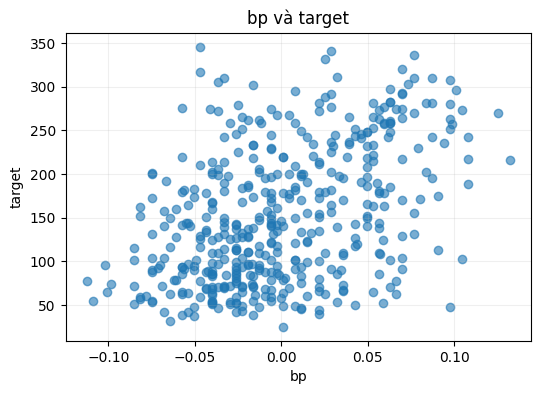

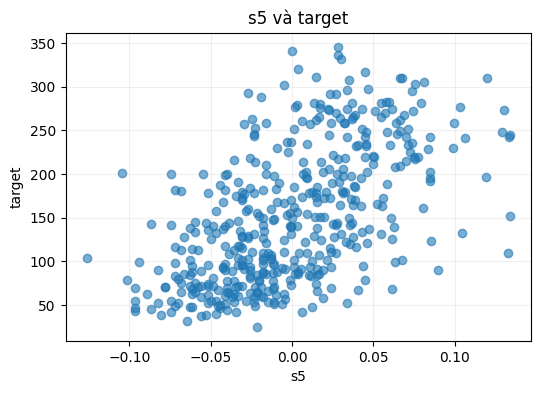

In [ ]:
corr = df[feature_cols + ["target"]].corr(numeric_only=True)

target_corr = (
    corr["target"]
    .drop("target")
    .sort_values(key=np.abs, ascending=False)
)

display(target_corr.to_frame("corr_with_target"))

for col in feature_cols:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["target"], alpha=0.6)
    plt.xlabel(col)
    plt.ylabel("target")
    plt.title(f"{col} và target")
    plt.grid(alpha=0.2)
    plt.show()



- **bmi và target:** Đám điểm có xu hướng đi lên khá rõ: BMI chuẩn hóa càng cao thì target thường càng cao. Tuy nhiên, tại cùng một mức BMI, target vẫn dao động nhiều.

- **bp và target:** Có xu hướng tăng cùng nhau nhưng các điểm phân tán rộng, xu hướng kém rõ hơn so với bmi và s5. Vì vậy, chỉ dùng bp sẽ khó dự đoán chính xác target.

- **s5 và target:** Đám điểm có xu hướng đi lên rõ, cho thấy quan hệ dương giữa s5 và target. Các điểm vẫn phân tán đáng kể nên s5 chưa giải thích hết sự thay đổi của target.

**Kết luận:** Cả ba feature đều thể hiện xu hướng tương quan dương với target. Trên biểu đồ, bmi và s5 có xu hướng rõ hơn bp; cần đối chiếu hệ số Pearson để so sánh chính xác mức độ tương quan. Đây là quan hệ thống kê, không chứng minh nhân quả.

# BÀI 2. SO SÁNH CÁC BỘ FEATURE

Huấn luyện Linear Regression với:
1. bmi.
2. bmi và bp.
3. Top 5 feature theo trị tuyệt đối tương quan với target.
4. Toàn bộ 10 feature.

Dùng cùng tập train/test để so sánh công bằng.
Top 5 được chọn trên tập train để tránh rò rỉ dữ liệu.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

train_df = X_train.copy()
train_df["target"] = y_train

abs_corr = (
    train_df.corr(numeric_only=True)["target"]
    .drop("target")
    .abs()
)

top_features = (
    abs_corr.sort_values(ascending=False)
    .head(5)
    .index.tolist()
)

print("Top 5 feature:", top_features)

Top 5 feature: ['bmi', 's5', 'bp', 's4', 's6']


Mã: huấn luyện bốn mô hình

In [ ]:
feature_sets = {
    "bmi": ["bmi"],
    "bmi + bp": ["bmi", "bp"],
    "Top 5 features": top_features,
    "Toàn bộ 10 features": X.columns.tolist()
}

results_features = []

for name, cols in feature_sets.items():
    model = LinearRegression()

    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results_features.append([name, mae, rmse, r2])

comparison_features = pd.DataFrame(
    results_features,
    columns=["Bộ feature", "MAE", "RMSE", "R2"]
)

display(comparison_features.round(4))

,Bộ feature,MAE,RMSE,R2
0,bmi,52.2600,63.7325,0.2334
1,bmi + bp,50.0441,61.1597,0.2940
2,Top 5 features,44.3288,53.8493,0.4527
3,Toàn bộ 10 features,42.7941,53.8534,0.4526


Chỉ dùng bmi: MAE = 52.2600, RMSE = 63.7325, R² = 0.2334. Đây là mô hình có kết quả kém nhất trong bốn bộ feature.

Dùng bmi + bp: MAE và RMSE giảm, R² tăng lên 0.2940. Việc thêm bp giúp cải thiện khả năng dự đoán so với chỉ dùng bmi.

Top 5 features: Kết quả cải thiện rõ rệt, với MAE = 44.3288, RMSE = 53.8493 và R² = 0.4527. Mô hình có RMSE thấp nhất và R² cao nhất, nhưng chỉ nhỉnh hơn rất ít so với dùng toàn bộ 10 feature.

Toàn bộ 10 features: Có MAE thấp nhất, đạt 42.7941. RMSE = 53.8534 và R² = 0.4526, gần như tương đương mô hình Top 5.

Kết luận: Trên tập test này, toàn bộ 10 feature tốt nhất theo MAE; Top 5 tốt nhất theo RMSE và R² nhưng chênh lệch rất nhỏ. Bộ Top 5 là lựa chọn gọn hơn mà vẫn giữ hiệu quả dự đoán gần tương đương bộ 10 feature.

# BÀI 3. SO SÁNH CÁC THUẬT TOÁN HỒI QUY

Sử dụng toàn bộ 10 feature và cùng tập train/test của bài 2.

Các thuật toán:
- Linear Regression.
- Ridge Regression.
- Decision Tree Regression.
- Support Vector Regression.
- Gradient Boosting Regression.

Ridge và SVR được kết hợp với StandardScaler.
Bộ chuẩn hóa chỉ được học trên tập train thông qua Pipeline.

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Decision Tree Regression": DecisionTreeRegressor(
        random_state=42
    ),

    "Support Vector Regression": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=100, epsilon=0.1)
    ),

    "Gradient Boosting Regression": GradientBoostingRegressor(
        random_state=42
    )
}

results_models = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results_models.append([name, mae, rmse, r2])

comparison_models = pd.DataFrame(
    results_models,
    columns=["Thuật toán", "MAE", "RMSE", "R2"]
)

display(comparison_models.round(4))

,Thuật toán,MAE,RMSE,R2
0,Linear Regression,42.7941,53.8534,0.4526
1,Ridge Regression,42.8120,53.7775,0.4541
2,Decision Tree Regression,54.5281,70.5464,0.0607
3,Support Vector Regression,39.4187,51.0641,0.5078
4,Gradient Boosting Regression,44.6033,53.8371,0.4529




- Linear Regression: MAE = 42.7941, RMSE = 53.8534 và R² = 0.4526, được dùng làm mốc so sánh.

- Ridge Regression: RMSE giảm nhẹ xuống 53.7775 và R² tăng lên 0.4541, nhưng MAE tăng nhẹ. Kết quả gần tương đương Linear Regression.

- Decision Tree Regression: Có kết quả kém nhất: MAE = 54.5281, RMSE = 70.5464 và R² = 0.0607. Cần đánh giá thêm trên tập train để kiểm tra khả năng quá khớp.

- Support Vector Regression: Có kết quả tốt nhất ở cả ba chỉ số: MAE thấp nhất = 39.4187, RMSE thấp nhất = 51.0641 và R² cao nhất = 0.5078.

- Gradient Boosting Regression: RMSE và R² gần tương đương Linear Regression, nhưng MAE cao hơn, đạt 44.6033. Với cấu hình hiện tại, mô hình chưa cho thấy cải thiện rõ rệt.

Kết luận: Với cách chia dữ liệu và các tham số đang sử dụng, SVR dự đoán tốt nhất trên tập test. Kết quả này chưa có nghĩa SVR luôn tốt nhất; cần cross-validation để đánh giá độ ổn định.
